# Day 12 — Seaborn + Advanced Exploratory Data Analysis
**Internship:** Data Analytics & Data Science  | **Task Day:** 12  | **Date:** 23 November 2026

**Source:** Day05_Retail_Sales_Dataset.csv (original Day 5 data, unchanged).

**Objectives:** distribution analysis, category analysis, outlier analysis, correlation heatmap, pairplot and 10 evidence-based observations.

## 1. Setup and load the dataset
Seaborn builds on Matplotlib. Pandas is used for grouping and numerical summaries. Keep the CSV in the same directory as this notebook.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
path = Path("Day05_Retail_Sales_Dataset.csv")
df = pd.read_csv(path)
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
print("Rows and columns:", df.shape)
print("Missing values:\n", df.isna().sum().to_string())
print("Duplicate Order_IDs:", df["Order_ID"].duplicated().sum())
display(df.head())

Rows and columns: (30, 10)
Missing values:
 Order_ID           0
Order_Date         0
Customer_Name      0
City               0
Category           0
Product            0
Quantity           0
Unit_Price         0
Sales              0
Customer_Rating    3
Duplicate Order_IDs: 0


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0


## 2. Dataset preparation and descriptive statistics
No values are fabricated or imputed. Missing ratings are omitted only for rating-specific plots and correlations.

In [2]:
numeric_cols = ["Quantity", "Unit_Price", "Sales", "Customer_Rating"]
category_summary = df.groupby("Category").agg(Orders=("Order_ID", "count"), Revenue=("Sales", "sum"), Average_Sale=("Sales", "mean")).sort_values("Revenue", ascending=False)
city_summary = df.groupby("City").agg(Orders=("Order_ID", "count"), Revenue=("Sales", "sum")).sort_values("Revenue", ascending=False)
print("Total revenue:", df["Sales"].sum())
display(df[numeric_cols].describe(), category_summary, city_summary)

Total revenue: 81870


,Quantity,Unit_Price,Sales,Customer_Rating
count,30.00000,30.000000,30.000000,27.000000
mean,3.00000,865.333333,2729.000000,4.222222
std,1.43839,453.155476,2136.342911,0.751068
min,1.00000,320.000000,320.000000,3.000000
25%,2.00000,402.500000,995.000000,4.000000
50%,3.00000,650.000000,2075.000000,4.000000
75%,4.00000,1100.000000,4125.000000,5.000000
max,5.00000,1500.000000,7500.000000,5.000000


,Orders,Revenue,Average_Sale
Category,,,
Electronics,7,36000,5142.857143
Home,7,24200,3457.142857
Clothing,8,14950,1868.750000
Grocery,8,6720,840.000000


,Orders,Revenue
City,,
Pune,12,33140
Nashik,6,24680
Nagpur,6,14970
Mumbai,6,9080


## 3. Chart 1: Sales distribution (histogram + KDE)
**Purpose / interpretation:** Shows whether order sales are concentrated at lower or higher amounts; a KDE is a smoothed estimate, not a fitted normal model.

**Axes:** X = Sales (INR); Y = Number of orders.

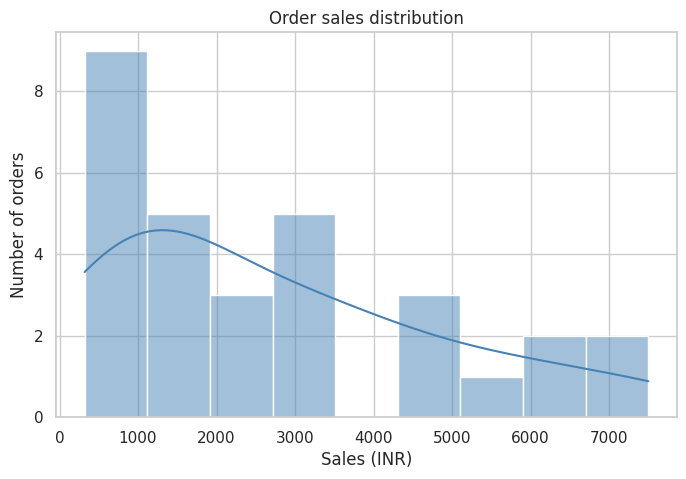

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="Sales", bins=9, kde=True, color="steelblue", ax=ax)
ax.set(title="Order sales distribution", xlabel="Sales (INR)", ylabel="Number of orders")
plt.show()

## 4. Chart 2: Orders by category (countplot)
**Purpose / interpretation:** Counts transactions in each category rather than summing revenue.

**Axes:** X = Category; Y = Number of orders.

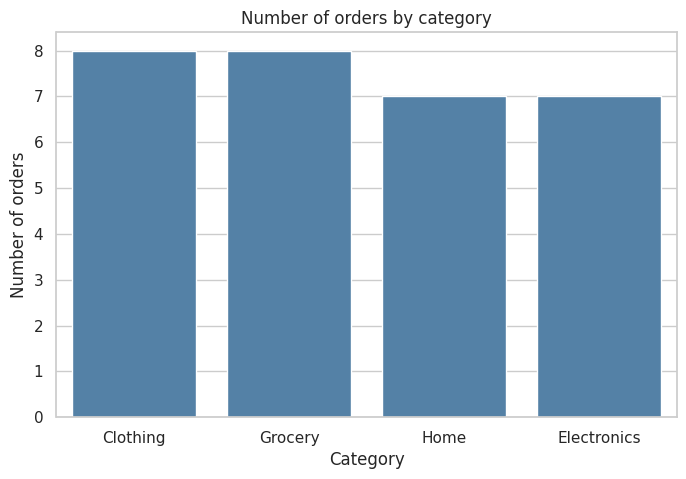

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x="Category", order=df["Category"].value_counts().index, color="steelblue", ax=ax)
ax.set(title="Number of orders by category", xlabel="Category", ylabel="Number of orders")
plt.show()

## 5. Chart 3: Sales spread by category (boxplot)
**Purpose / interpretation:** Compares medians, quartiles, and potential unusually high or low sales within each category.

**Axes:** X = Category; Y = Sales (INR).

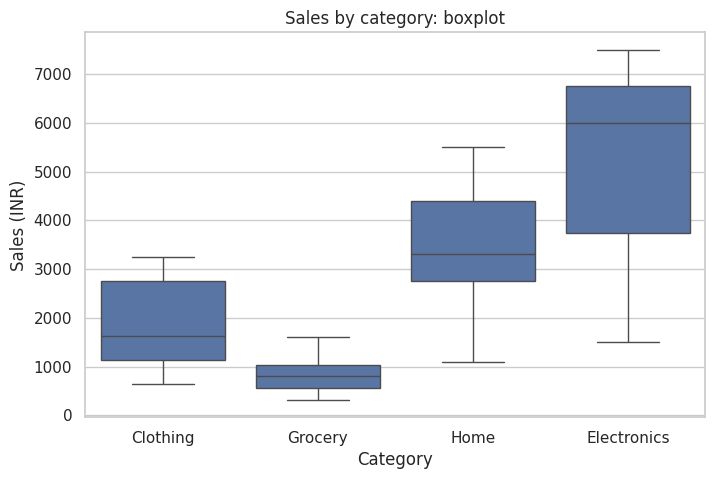

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Category", y="Sales", ax=ax)
ax.set(title="Sales by category: boxplot", xlabel="Category", ylabel="Sales (INR)")
plt.show()

## 6. Chart 4: Sales distribution by category (violin)
**Purpose / interpretation:** Shows a smoothed distribution for each category; with a small sample, violin shapes are approximate.

**Axes:** X = Category; Y = Sales (INR).

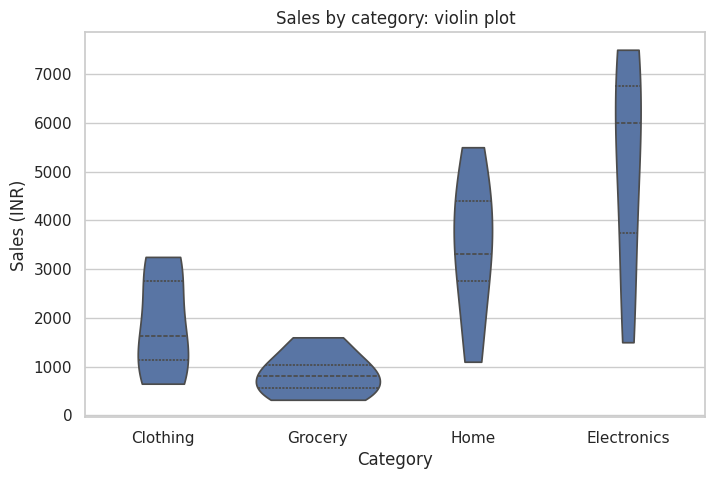

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="Category", y="Sales", inner="quartile", cut=0, ax=ax)
ax.set(title="Sales by category: violin plot", xlabel="Category", ylabel="Sales (INR)")
plt.show()

## 7. Chart 5: Numeric correlation heatmap
**Purpose / interpretation:** Pearson correlations range from -1 to +1. Missing ratings are omitted pairwise by pandas.

**Axes:** X = Numeric variables; Y = Numeric variables.

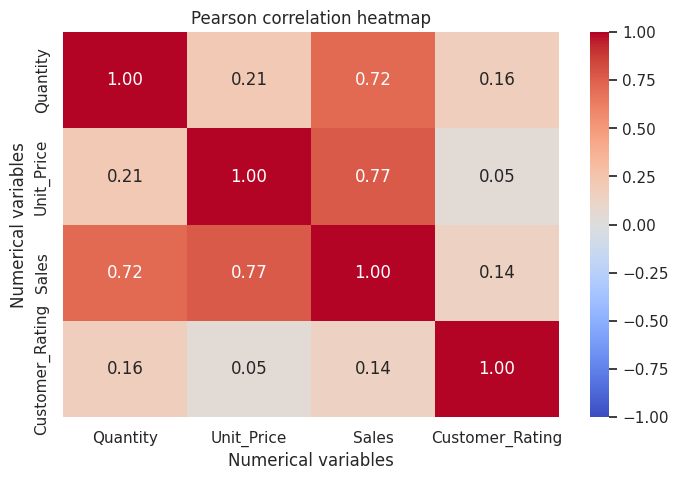

In [7]:
correlation_matrix = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set(title="Pearson correlation heatmap", xlabel="Numerical variables", ylabel="Numerical variables")
plt.show()

## 8. Chart 6: Pairwise relationships (pairplot)
**Purpose / interpretation:** Scatterplots reveal associations and histograms show individual distributions; pairplot does not imply causation.

**Axes:** X = Numeric variables; Y = Numeric variables.

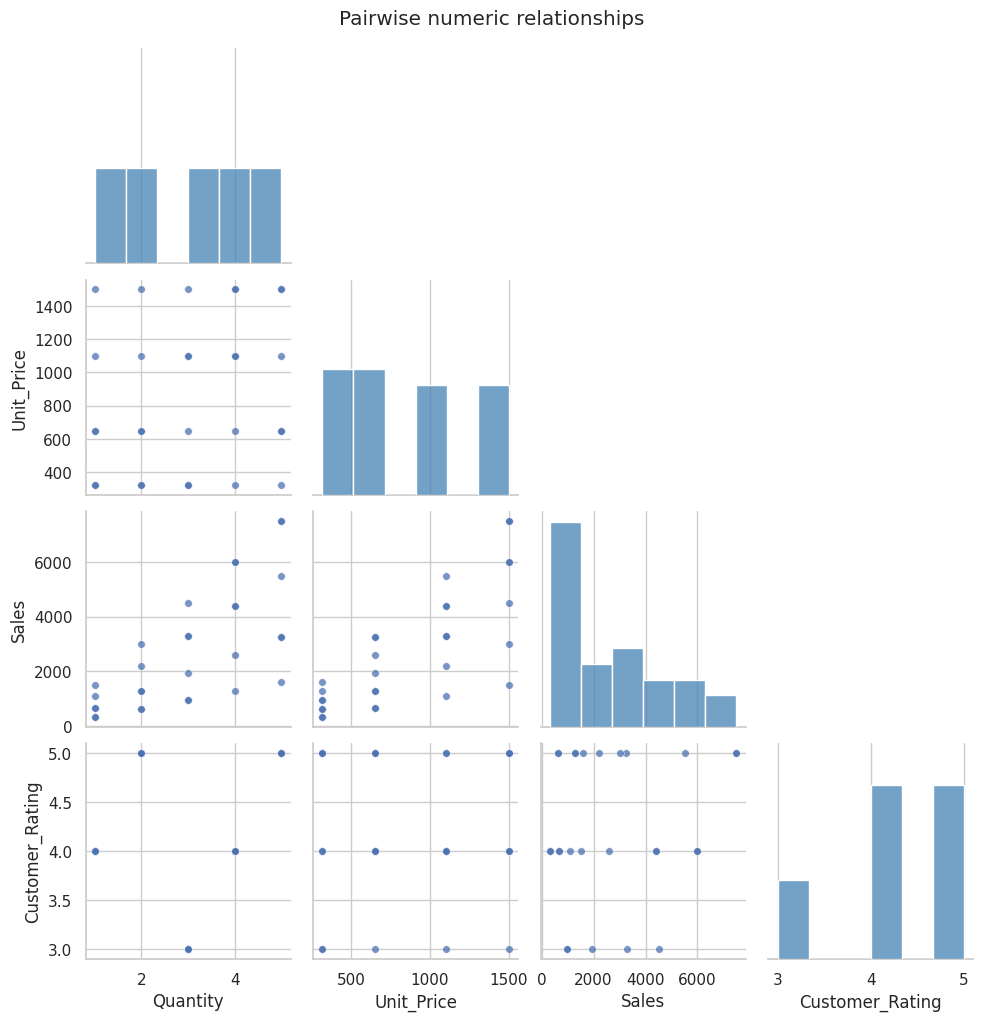

In [8]:
pair = sns.pairplot(df[numeric_cols], diag_kind="hist", diag_kws={"color":"steelblue"}, corner=True, plot_kws={"alpha": 0.75, "s": 30})
pair.fig.suptitle("Pairwise numeric relationships", y=1.02)
plt.show()

## 9. Chart 7: Orders by city (countplot)
**Purpose / interpretation:** Compares order frequency across cities, not revenue.

**Axes:** X = City; Y = Number of orders.

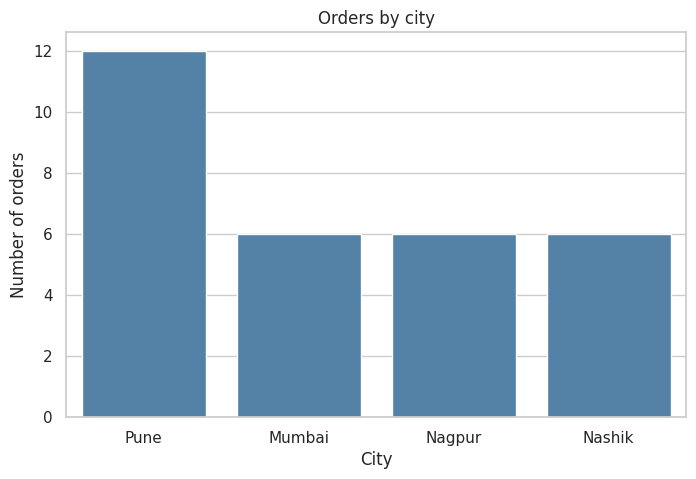

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x="City", order=df["City"].value_counts().index, color="steelblue", ax=ax)
ax.set(title="Orders by city", xlabel="City", ylabel="Number of orders")
plt.show()

## 10. Chart 8: Customer rating distribution
**Purpose / interpretation:** Uses only non-missing customer ratings; missing ratings are not assigned zero.

**Axes:** X = Customer rating; Y = Number of rated orders.

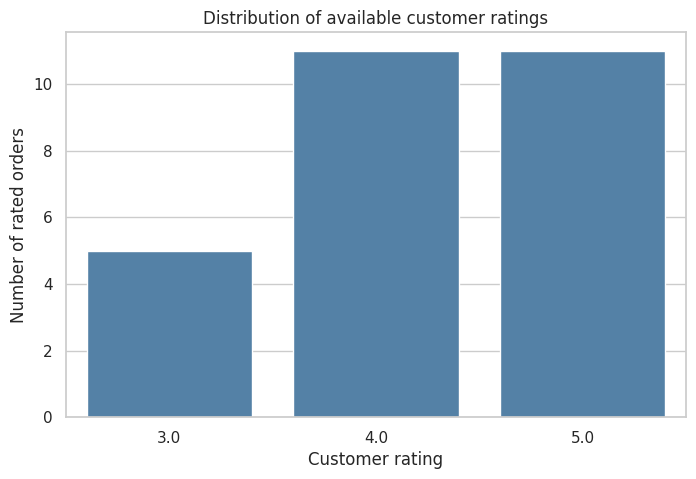

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df.dropna(subset=["Customer_Rating"]), x="Customer_Rating", color="steelblue", ax=ax)
ax.set(title="Distribution of available customer ratings", xlabel="Customer rating", ylabel="Number of rated orders")
plt.show()

## 11. Chart 9: Quantity vs sales by category
**Purpose / interpretation:** Shows how order quantity relates to sales; unit price also affects sales.

**Axes:** X = Quantity; Y = Sales (INR).

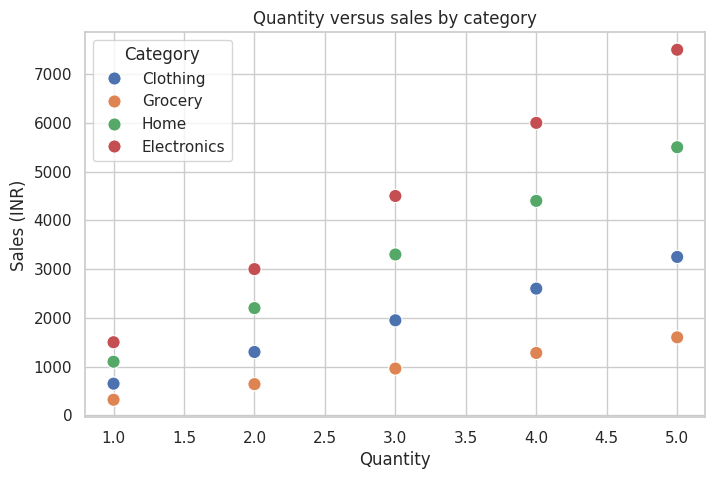

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="Quantity", y="Sales", hue="Category", s=90, ax=ax)
ax.set(title="Quantity versus sales by category", xlabel="Quantity", ylabel="Sales (INR)")
plt.show()

## 12. Chart 10: Revenue by category
**Purpose / interpretation:** Compares category total revenue, a different metric from transaction count.

**Axes:** X = Category; Y = Total sales (INR).

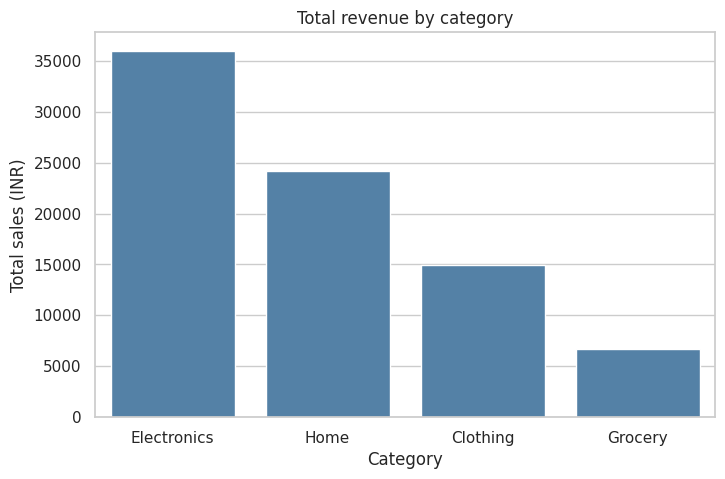

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=category_summary.index, y=category_summary["Revenue"].values, color="steelblue", ax=ax)
ax.set(title="Total revenue by category", xlabel="Category", ylabel="Total sales (INR)")
plt.show()

## 13. Outlier detection using the IQR rule
**Formula:** IQR = Q3 - Q1. Lower fence = Q1 - 1.5 × IQR; upper fence = Q3 + 1.5 × IQR. These are statistical flags, not automatic errors.

In [13]:
q1, q3 = df["Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_rows = df.loc[(df["Sales"] < lower_fence) | (df["Sales"] > upper_fence)]
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Lower fence={lower_fence:.2f}, Upper fence={upper_fence:.2f}")
print("Outlier count:", len(outlier_rows))
display(outlier_rows)

Q1=995.00, Q3=4125.00, IQR=3130.00
Lower fence=-3700.00, Upper fence=8820.00
Outlier count: 0


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating


## 14. Ten data-supported observations
The following are computed from the dataset, not assumed.

In [14]:
correlations = df[numeric_cols].corr()
observations = [
    f"Total revenue is INR {df.Sales.sum():,.0f} across {len(df)} orders; average order sales are INR {df.Sales.mean():,.2f}.",
    f"{category_summary.index[0]} leads category revenue with INR {category_summary.Revenue.iloc[0]:,.0f} ({category_summary.Revenue.iloc[0]/df.Sales.sum():.1%} of total).",
    f"{category_summary.index[-1]} has the lowest category revenue at INR {category_summary.Revenue.iloc[-1]:,.0f}.",
    f"{city_summary.index[0]} leads city revenue with INR {city_summary.Revenue.iloc[0]:,.0f} from {city_summary.Orders.iloc[0]} orders.",
    f"The most frequent category is {df.Category.value_counts().idxmax()} with {df.Category.value_counts().max()} orders.",
    f"Sales median is INR {df.Sales.median():,.0f}; Q1=INR {q1:,.0f}, Q3=INR {q3:,.0f}, IQR=INR {iqr:,.0f}.",
    f"IQR lower fence is INR {lower_fence:,.0f} and upper fence is INR {upper_fence:,.0f}; {len(outlier_rows)} records are flagged.",
    f"Quantity and sales correlation is {correlations.loc['Quantity','Sales']:.3f}; correlation does not prove causation.",
    f"Unit price and sales correlation is {correlations.loc['Unit_Price','Sales']:.3f}; sales equals quantity multiplied by unit price.",
    f"Customer rating is missing for {df.Customer_Rating.isna().sum()} orders ({df.Customer_Rating.isna().mean():.1%}); missing values are excluded from rating analysis."
]
for number, observation in enumerate(observations, 1):
    print(f"{number}. {observation}")

1. Total revenue is INR 81,870 across 30 orders; average order sales are INR 2,729.00.
2. Electronics leads category revenue with INR 36,000 (44.0% of total).
3. Grocery has the lowest category revenue at INR 6,720.
4. Pune leads city revenue with INR 33,140 from 12 orders.
5. The most frequent category is Clothing with 8 orders.
6. Sales median is INR 2,075; Q1=INR 995, Q3=INR 4,125, IQR=INR 3,130.
7. IQR lower fence is INR -3,700 and upper fence is INR 8,820; 0 records are flagged.
8. Quantity and sales correlation is 0.715; correlation does not prove causation.
9. Unit price and sales correlation is 0.771; sales equals quantity multiplied by unit price.
10. Customer rating is missing for 3 orders (10.0%); missing values are excluded from rating analysis.


## 15. Conclusions and limitations
- This is a small **30-order** retail sample, so findings are descriptive and should not be generalized to all customers.
- Category and city comparisons use recorded transactions only.
- KDE and violin plots can be unstable with small samples.
- A correlation is not evidence of a causal effect.
- Three missing customer ratings are left missing.
- **Proof for submission:** capture VS Code screenshots showing successful Run All and key charts; the accompanying PDF includes actual generated chart images.